Enter your OpenWeatherMap API Key:  ········


Weather data retrieved successfully!

WEATHER DATA:
                  Date  Temperature  Min_Temperature  Max_Temperature  \
0  2026-11-15 06:00:00        28.41            28.41            29.59   
1  2026-11-15 09:00:00        29.48            29.48            31.62   
2  2026-11-15 12:00:00        26.81            26.01            26.81   
3  2026-11-15 15:00:00        22.43            22.43            22.43   
4  2026-11-15 18:00:00        21.34            21.34            21.34   

   Humidity  Wind_Speed  Precipitation           Weather  Latitude  Longitude  
0        45        2.57              0  scattered clouds   18.5196    73.8553  
1        38        1.26              0  scattered clouds   18.5196    73.8553  
2        35        0.68              0  scattered clouds   18.5196    73.8553  
3        33        1.05              0        few clouds   18.5196    73.8553  
4        39        1.97              0     broken clouds   18.5196    73.8553  

DATASET INFORMATION:
<class 

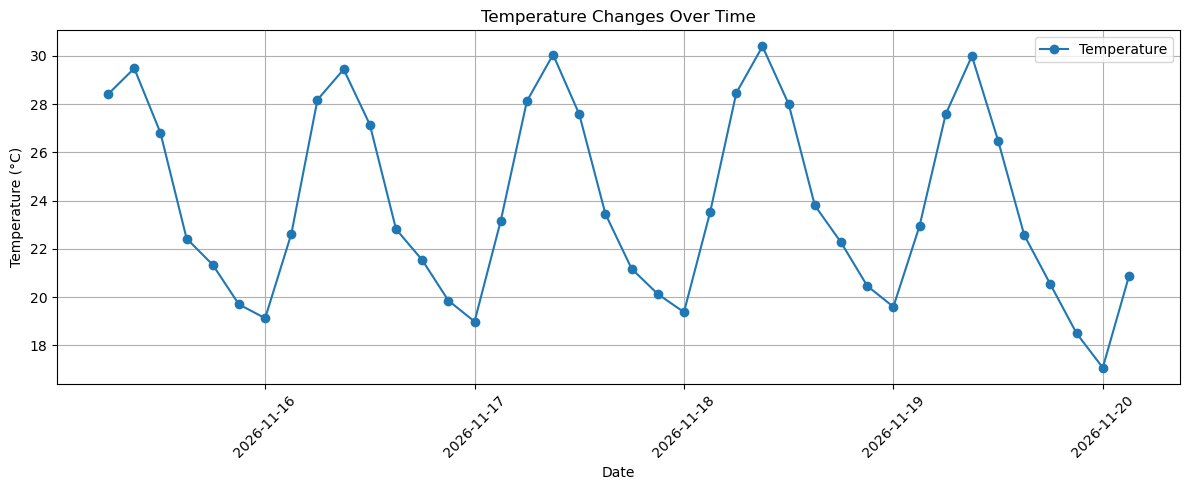

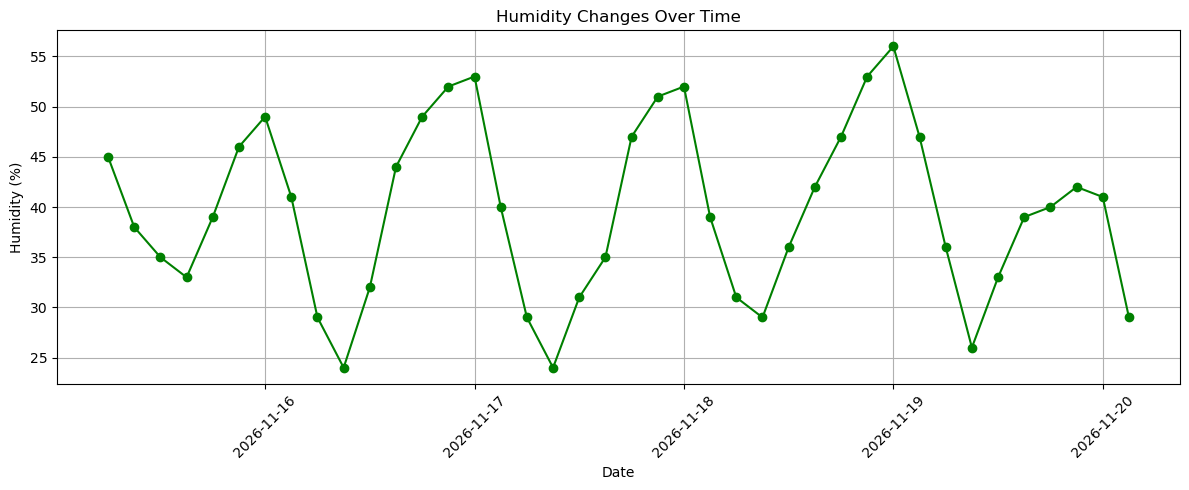

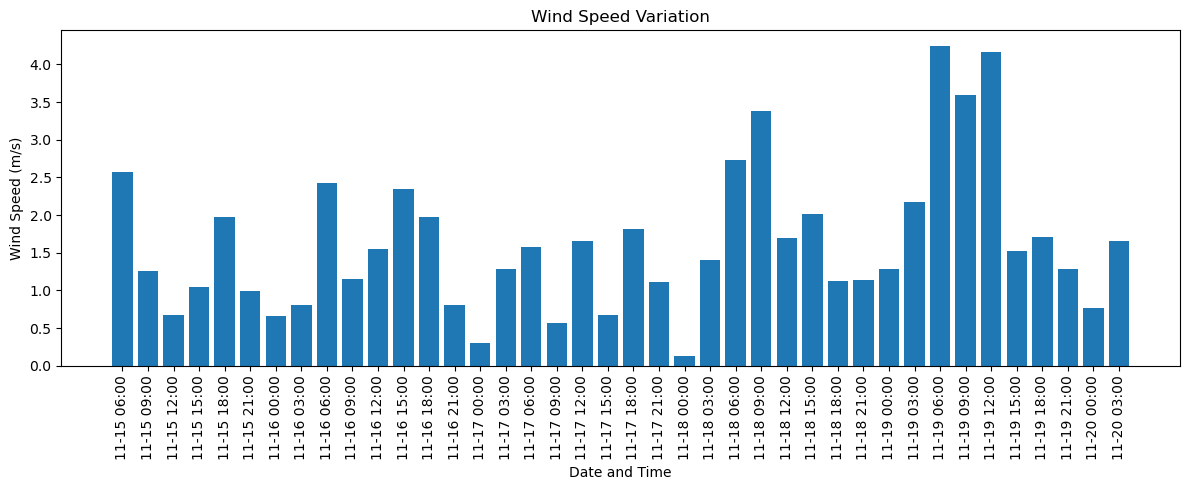

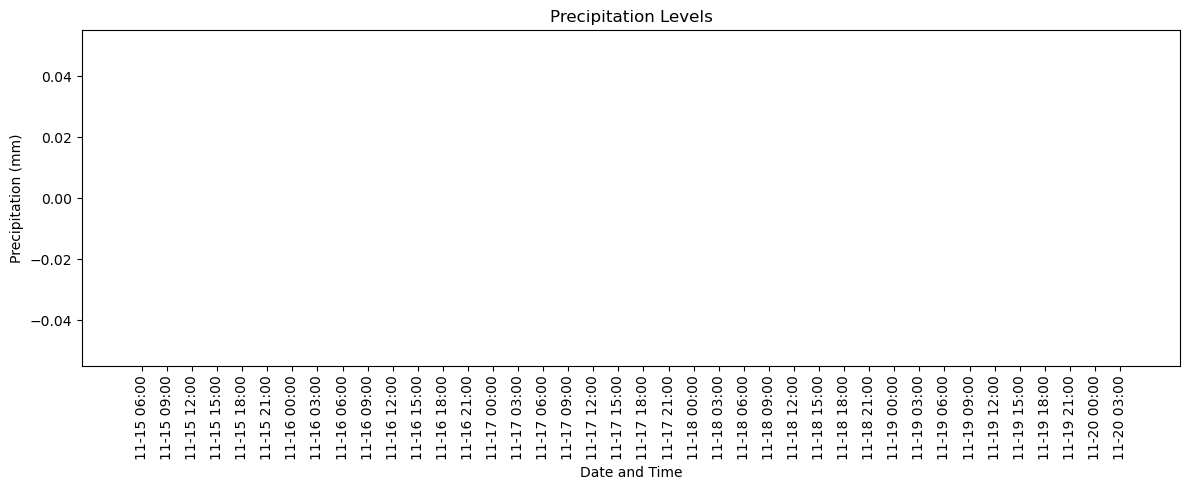

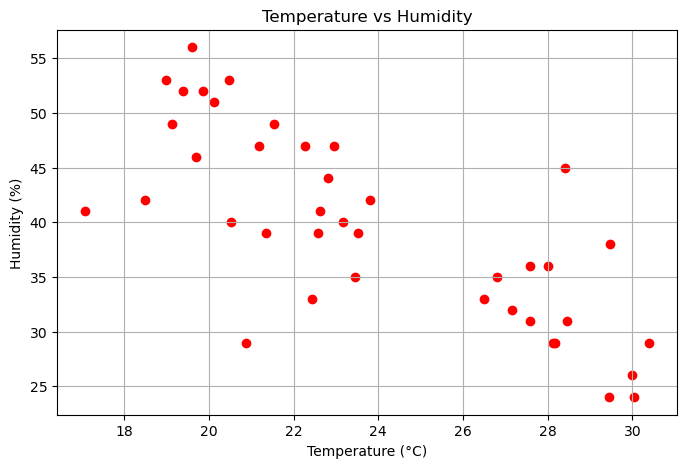

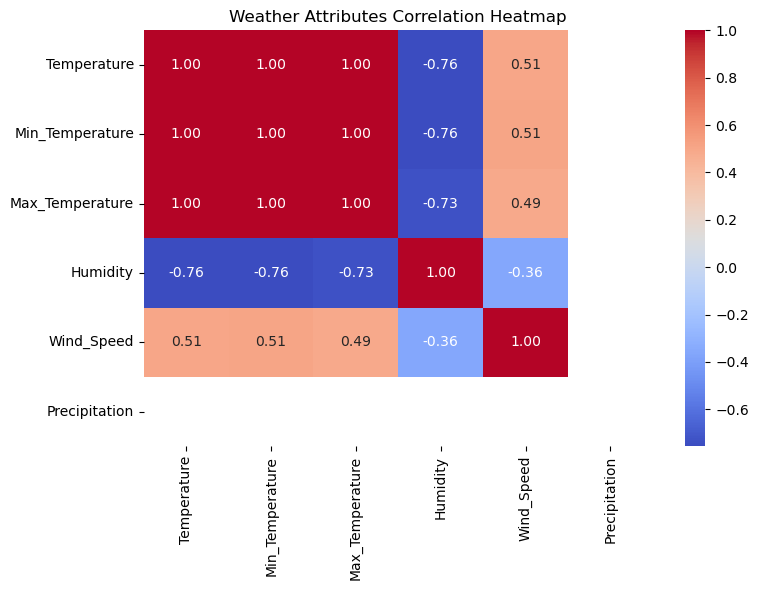

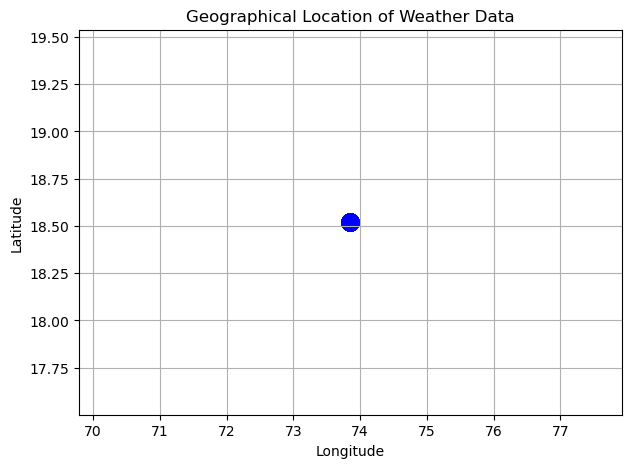


Weather data saved successfully!

PRACTICAL 2 EXECUTED SUCCESSFULLY!


In [1]:
#pip install requests pandas numpy matplotlib seaborn
#key : fb365aa6104829b44455572365ff3b4e
# ============================================================
# PRACTICAL 2: ANALYZING WEATHER DATA FROM OPENWEATHERMAP
# ============================================================

# Step 1: Import required libraries

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass


# ============================================================
# Step 2: Obtain API key and specify location
# ============================================================

API_KEY = getpass("Enter your OpenWeatherMap API Key: ")

city = "Pune"
country = "IN"

# API URL
url = "https://api.openweathermap.org/data/2.5/forecast"

# Parameters
params = {
    "q": f"{city},{country}",
    "appid": API_KEY,
    "units": "metric"
}


# ============================================================
# Step 3: Interact with OpenWeatherMap API
# ============================================================

response = requests.get(url, params=params, timeout=30)

if response.status_code == 200:

    weather_data = response.json()

    print("Weather data retrieved successfully!")

else:

    print("Error:", response.status_code)
    print(response.json())

    raise Exception("Unable to retrieve weather data. Check API key and location.")


# ============================================================
# Step 4: Extract relevant weather attributes
# ============================================================

weather_list = []

for item in weather_data["list"]:

    weather_list.append({

        "Date": item["dt_txt"],

        "Temperature": item["main"].get("temp"),

        "Min_Temperature": item["main"].get("temp_min"),

        "Max_Temperature": item["main"].get("temp_max"),

        "Humidity": item["main"].get("humidity"),

        "Wind_Speed": item["wind"].get("speed"),

        "Precipitation": item.get("rain", {}).get("3h", 0),

        "Weather": item["weather"][0].get("description"),

        "Latitude": weather_data["city"]["coord"]["lat"],

        "Longitude": weather_data["city"]["coord"]["lon"]

    })


# Convert extracted data into DataFrame

df = pd.DataFrame(weather_list)

print("\nWEATHER DATA:")
print(df.head())


# ============================================================
# Step 5: Explore weather dataset
# ============================================================

print("\nDATASET INFORMATION:")
df.info()

print("\nDESCRIPTIVE STATISTICS:")
print(df.describe())

print("\nMISSING VALUES:")
print(df.isnull().sum())


# ============================================================
# Step 6: Data cleaning and preprocessing
# ============================================================

# Convert Date into datetime format

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert numeric columns into appropriate data types

numeric_columns = [
    "Temperature",
    "Min_Temperature",
    "Max_Temperature",
    "Humidity",
    "Wind_Speed",
    "Precipitation"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Handle missing values

df["Precipitation"] = df["Precipitation"].fillna(0)

df = df.dropna(
    subset=["Date", "Temperature", "Humidity", "Wind_Speed"]
)

# Remove duplicate records

df = df.drop_duplicates()

# Sort records by date

df = df.sort_values("Date").reset_index(drop=True)

print("\nCLEANED WEATHER DATA:")
print(df.head())

print("\nMISSING VALUES AFTER CLEANING:")
print(df.isnull().sum())


# ============================================================
# Step 7: Data modeling and weather analysis
# ============================================================

# Calculate average temperature

avg_temp = df["Temperature"].mean()

# Calculate maximum temperature

max_temp = df["Temperature"].max()

# Calculate minimum temperature

min_temp = df["Temperature"].min()

# Calculate average humidity

avg_humidity = df["Humidity"].mean()

# Calculate average wind speed

avg_wind = df["Wind_Speed"].mean()

# Calculate total forecast precipitation

total_rain = df["Precipitation"].sum()

print("\nWEATHER STATISTICS")

print("Average Temperature:", round(avg_temp, 2), "°C")

print("Maximum Temperature:", round(max_temp, 2), "°C")

print("Minimum Temperature:", round(min_temp, 2), "°C")

print("Average Humidity:", round(avg_humidity, 2), "%")

print("Average Wind Speed:", round(avg_wind, 2), "m/s")

print("Total Forecast Precipitation:", round(total_rain, 2), "mm")


# ============================================================
# Step 8: Daily weather aggregation
# ============================================================

df["Date_Only"] = df["Date"].dt.date

daily_weather = df.groupby("Date_Only").agg({

    "Temperature": "mean",

    "Min_Temperature": "min",

    "Max_Temperature": "max",

    "Humidity": "mean",

    "Wind_Speed": "mean",

    "Precipitation": "sum"

})

print("\nDAILY WEATHER SUMMARY:")
print(daily_weather)


# ============================================================
# Step 9: Visualization - Temperature changes over time
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["Temperature"],
    marker="o",
    label="Temperature"
)

plt.title("Temperature Changes Over Time")

plt.xlabel("Date")

plt.ylabel("Temperature (°C)")

plt.xticks(rotation=45)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# Step 10: Visualization - Humidity changes
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["Humidity"],
    color="green",
    marker="o"
)

plt.title("Humidity Changes Over Time")

plt.xlabel("Date")

plt.ylabel("Humidity (%)")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# Step 11: Visualization - Wind speed
# ============================================================

plt.figure(figsize=(12, 5))

plt.bar(
    df["Date"].dt.strftime("%m-%d %H:%M"),
    df["Wind_Speed"]
)

plt.title("Wind Speed Variation")

plt.xlabel("Date and Time")

plt.ylabel("Wind Speed (m/s)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()


# ============================================================
# Step 12: Visualization - Precipitation
# ============================================================

plt.figure(figsize=(12, 5))

plt.bar(
    df["Date"].dt.strftime("%m-%d %H:%M"),
    df["Precipitation"],
    color="skyblue"
)

plt.title("Precipitation Levels")

plt.xlabel("Date and Time")

plt.ylabel("Precipitation (mm)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()


# ============================================================
# Step 13: Relationship between temperature and humidity
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Temperature"],
    df["Humidity"],
    color="red"
)

plt.title("Temperature vs Humidity")

plt.xlabel("Temperature (°C)")

plt.ylabel("Humidity (%)")

plt.grid(True)

plt.show()


# ============================================================
# Step 14: Correlation analysis using heatmap
# ============================================================

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Weather Attributes Correlation Heatmap")

plt.tight_layout()

plt.show()


# ============================================================
# Step 15: Geographical visualization
# ============================================================

plt.figure(figsize=(7, 5))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    s=150,
    color="blue"
)

plt.title("Geographical Location of Weather Data")

plt.xlabel("Longitude")

plt.ylabel("Latitude")

plt.grid(True)

plt.show()


# ============================================================
# Step 16: Save the weather dataset
# ============================================================

df.to_csv("weather_data.csv", index=False)

daily_weather.to_csv("daily_weather_summary.csv")

print("\nWeather data saved successfully!")

print("\nPRACTICAL 2 EXECUTED SUCCESSFULLY!")
